# 02_qa
Notebook khám phá cá nhân. Đưa logic dùng lại vào src/airbnb; không dùng notebook làm pipeline chính.


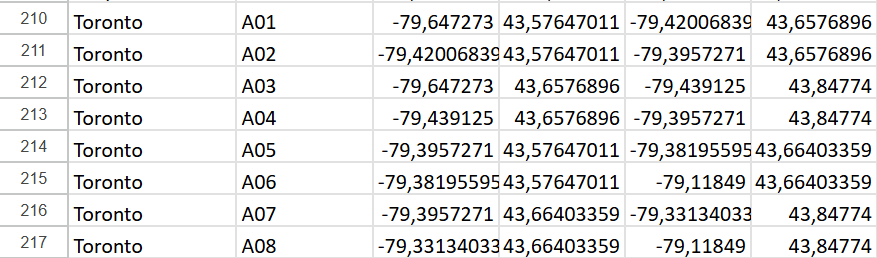

In [1]:
import sys
from pathlib import Path
import json
import pandas as pd
import geopandas as gpd

# Trỏ đường dẫn gốc của repo để import được module chung
ROOT = Path().resolve().parent # Điều chỉnh '.parent' tùy độ sâu thư mục notebook của bạn
sys.path.insert(0, str(ROOT / 'src'))

from airbnb.io import load_config

# Load config
cfg, root_path = load_config(ROOT / "configs/toronto.yaml")
final_snapshot = cfg['snapshots'][-1]
print("Mốc thời gian cuối cùng (để tính giá):", final_snapshot)

Mốc thời gian cuối cùng (để tính giá): 2026-06-15


Các loại cờ QA hiện có:
qa_flags
price_missing_final    20
Name: count, dtype: int64


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

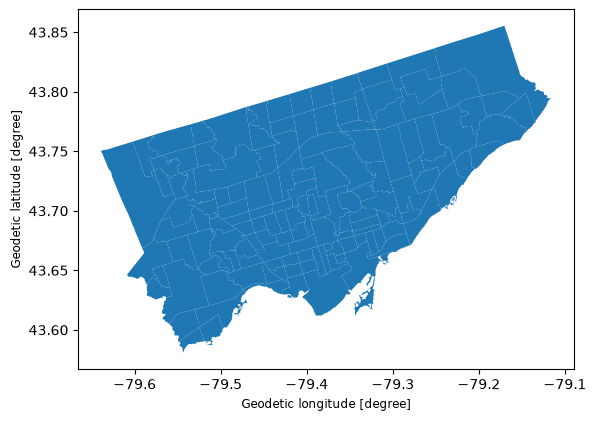

In [2]:
# Tải bảng listing đã qua bước QA
df_listings = pd.read_csv(ROOT / "data/processed/real/listings.csv")

# Xem thử các dòng bị gắn cờ lỗi
print("Các loại cờ QA hiện có:")
print(df_listings['qa_flags'].value_counts())

# Tải GeoJSON của mốc cuối cùng để vẽ bản đồ
geojson_path = ROOT / "data/raw" / final_snapshot / "neighbourhoods.geojson"
gdf_neighbourhoods = gpd.read_file(geojson_path)
gdf_neighbourhoods.plot() # Kiểm tra nhanh hình dáng bản đồ Toronto

In [3]:
df_listings

,snapshot_date,listing_id,host_id,price,room_type,analysis_area,neighbourhood_cleansed,latitude,longitude,qa_flags
0,2025-09-11,50110,195095,160.00,Entire home/apt,A07,Church-Yonge Corridor,43.668990,-79.385590,NaN
1,2025-09-11,84151,195095,128.00,Entire home/apt,A07,Rosedale-Moore Park,43.671380,-79.384240,NaN
2,2025-09-11,153000,735795,450.00,Entire home/apt,A05,Waterfront Communities-The Island,43.644940,-79.391230,NaN
3,2025-09-11,393873,1870492,115.00,Entire home/apt,A02,Niagara,43.644550,-79.403120,NaN
4,2025-09-11,573892,2175675,144.00,Entire home/apt,A06,Waterfront Communities-The Island,43.642780,-79.379850,NaN
...,...,...,...,...,...,...,...,...,...,...
3995,2026-06-15,1497193484403289223,399730808,593.41,Entire home/apt,A04,Casa Loma,43.686807,-79.404718,NaN
3996,2026-06-15,1498868475731074722,716257102,265.00,Entire home/apt,A06,Moss Park,43.657375,-79.374087,NaN
3997,2026-06-15,1499441611704031356,715927424,240.00,Entire home/apt,A06,Moss Park,43.657262,-79.374209,NaN
3998,2026-06-15,1502977270045215452,377261294,287.62,Entire home/apt,A05,Waterfront Communities-The Island,43.642750,-79.389290,NaN


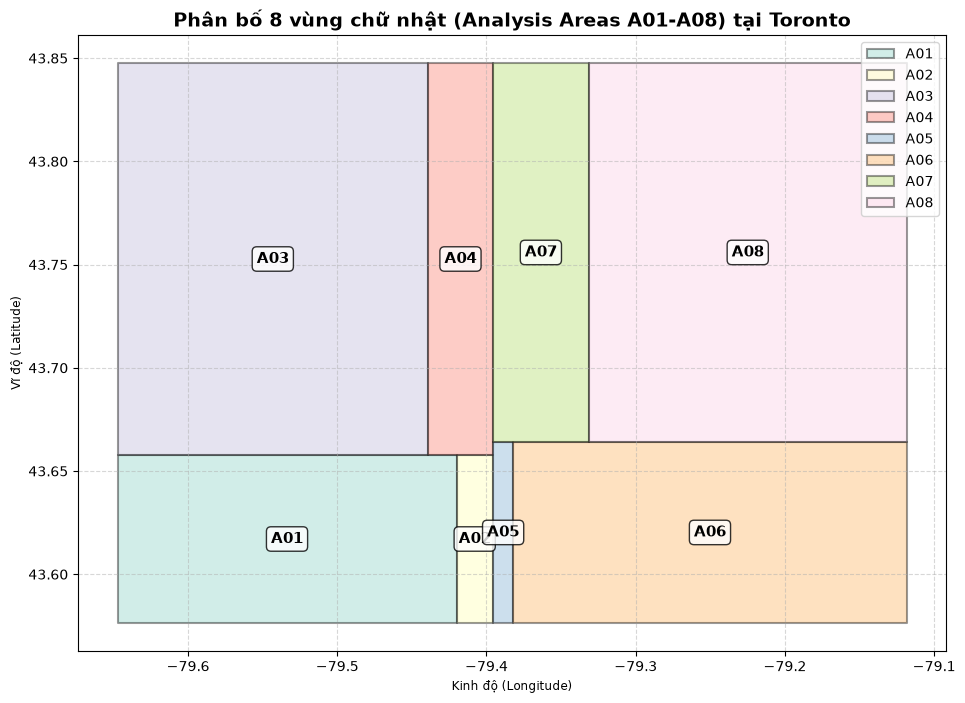

In [4]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

# 1. Khai báo tọa độ 8 vùng chữ nhật từ file cấu hình/workbook
areas_data = [
    {"area": "A01", "lon_min": -79.647273, "lat_min": 43.57647011, "lon_max": -79.42006839, "lat_max": 43.6576896},
    {"area": "A02", "lon_min": -79.42006839, "lat_min": 43.57647011, "lon_max": -79.3957271, "lat_max": 43.6576896},
    {"area": "A03", "lon_min": -79.647273, "lat_min": 43.6576896, "lon_max": -79.439125, "lat_max": 43.84774},
    {"area": "A04", "lon_min": -79.439125, "lat_min": 43.6576896, "lon_max": -79.3957271, "lat_max": 43.84774},
    {"area": "A05", "lon_min": -79.3957271, "lat_min": 43.57647011, "lon_max": -79.38195595, "lat_max": 43.66403359},
    {"area": "A06", "lon_min": -79.38195595, "lat_min": 43.57647011, "lon_max": -79.11849, "lat_max": 43.66403359},
    {"area": "A07", "lon_min": -79.3957271, "lat_min": 43.66403359, "lon_max": -79.33134033, "lat_max": 43.84774},
    {"area": "A08", "lon_min": -79.33134033, "lat_min": 43.66403359, "lon_max": -79.11849, "lat_max": 43.84774},
]

# 2. Chuyển đổi tọa độ thành các khối Polygon hình chữ nhật
boxes = []
for item in areas_data:
    geom = box(item["lon_min"], item["lat_min"], item["lon_max"], item["lat_max"])
    boxes.append({"analysis_area": item["area"], "geometry": geom})

gdf_areas = gpd.GeoDataFrame(boxes, crs="EPSG:4326")

# 3. Vẽ bản đồ phân bố 8 vùng A01-A08
fig, ax = plt.subplots(figsize=(12, 8))

# Tô màu 8 khung chữ nhật
gdf_areas.plot(
    ax=ax,
    column="analysis_area",
    cmap="Set3",
    alpha=0.4,
    edgecolor="black",
    linewidth=1.5,
    legend=True
)

# Thêm nhãn mã vùng (A01, A02...) ở tâm từng hình chữ nhật
for _, row in gdf_areas.iterrows():
    centroid = row.geometry.centroid
    ax.annotate(
        text=row["analysis_area"],
        xy=(centroid.x, centroid.y),
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", lw=1, alpha=0.8)
    )

# 4. Trình bày biểu đồ
ax.set_title("Phân bố 8 vùng chữ nhật (Analysis Areas A01-A08) tại Toronto", fontsize=14, fontweight="bold")
ax.set_xlabel("Kinh độ (Longitude)")
ax.set_ylabel("Vĩ độ (Latitude)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

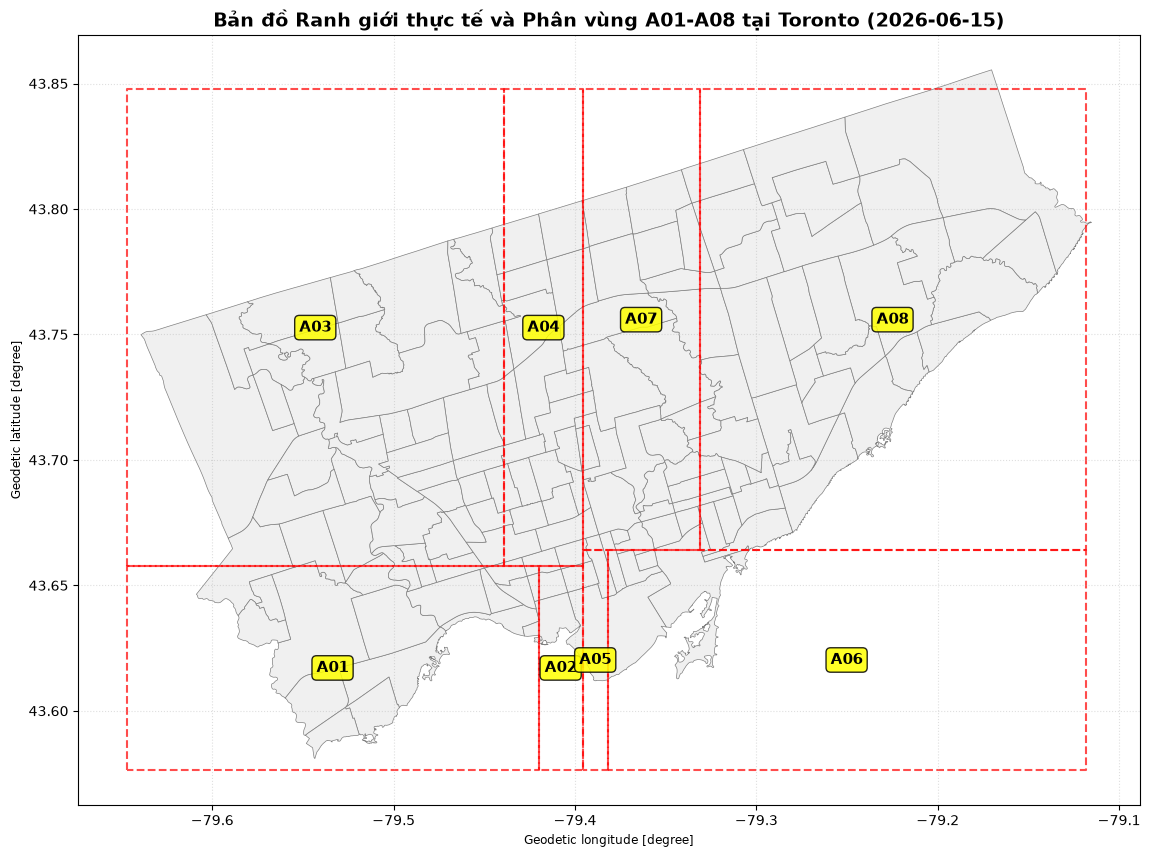

In [5]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

# 1. Khai báo 8 vùng chữ nhật A01 - A08
TORONTO_AREAS = [
    {"area": "A01", "lon_min": -79.647273, "lat_min": 43.57647011, "lon_max": -79.42006839, "lat_max": 43.6576896},
    {"area": "A02", "lon_min": -79.42006839, "lat_min": 43.57647011, "lon_max": -79.3957271, "lat_max": 43.6576896},
    {"area": "A03", "lon_min": -79.647273, "lat_min": 43.6576896, "lon_max": -79.439125, "lat_max": 43.84774},
    {"area": "A04", "lon_min": -79.439125, "lat_min": 43.6576896, "lon_max": -79.3957271, "lat_max": 43.84774},
    {"area": "A05", "lon_min": -79.3957271, "lat_min": 43.57647011, "lon_max": -79.38195595, "lat_max": 43.66403359},
    {"area": "A06", "lon_min": -79.38195595, "lat_min": 43.57647011, "lon_max": -79.11849, "lat_max": 43.66403359},
    {"area": "A07", "lon_min": -79.3957271, "lat_min": 43.66403359, "lon_max": -79.33134033, "lat_max": 43.84774},
    {"area": "A08", "lon_min": -79.33134033, "lat_min": 43.66403359, "lon_max": -79.11849, "lat_max": 43.84774},
]

# Tạo GeoDataFrame cho 8 vùng A01-A08
boxes = [
    {"analysis_area": item["area"], "geometry": box(item["lon_min"], item["lat_min"], item["lon_max"], item["lat_max"])}
    for item in TORONTO_AREAS
]
gdf_areas = gpd.GeoDataFrame(boxes, crs="EPSG:4326")

# 2. Đọc file GeoJSON ranh giới hành chính thực tế
final_snapshot = cfg['snapshots'][-1]
geojson_path = ROOT / "data/raw" / final_snapshot / "neighbourhoods.geojson"
gdf_hoods = gpd.read_file(geojson_path)

# 3. Khởi tạo biểu đồ
fig, ax = plt.subplots(figsize=(14, 10))

# Vẽ bản đồ ranh giới thật (tô màu xám nhẹ)
gdf_hoods.plot(ax=ax, color='#f0f0f0', edgecolor='gray', linewidth=0.5)

# Vẽ nét đứt thể hiện ranh giới 8 vùng chữ nhật A01-A08
gdf_areas.plot(ax=ax, facecolor='none', edgecolor='red', linestyle='--', linewidth=1.5, alpha=0.7)

# --- BƯỚC THÊM CHÚ THÍCH TÊN VÙNG A01 - A08 ---
for _, row in gdf_areas.iterrows():
    # Lấy tọa độ tâm của hình chữ nhật
    c = row.geometry.centroid
    
    ax.annotate(
        text=row["analysis_area"],                # Nhãn tên (A01, A02,...)
        xy=(c.x, c.y),                             # Tọa độ (kinh độ, vĩ độ) của tâm
        ha="center",                               # Căn giữa theo chiều ngang
        va="center",                               # Căn giữa theo chiều dọc
        fontsize=11,                               # Cỡ chữ
        fontweight="bold",                         # In đậm
        color="black",                             # Màu chữ
        bbox=dict(
            boxstyle="round,pad=0.3",              # Nền bo tròn xung quanh chữ
            fc="yellow",                           # Màu nền vàng giúp nhãn nổi bật
            ec="black",                            # Viền màu đen
            lw=1, 
            alpha=0.85
        )
    )

ax.set_title(f"Bản đồ Ranh giới thực tế và Phân vùng A01-A08 tại Toronto ({final_snapshot})", fontsize=14, fontweight='bold')
plt.grid(True, linestyle=":", alpha=0.4)
plt.show()

In [6]:
df_listings.groupby(by = 'snapshot_date')['price'].median()


snapshot_date
2025-09-11    174.000
2025-12-12        NaN
2026-03-19    189.400
2026-06-15    213.545
Name: price, dtype: float64

# 1. Quy mô listings của mỗi snapshot

In [7]:
df_listings[df_listings['price'].isna()].groupby('snapshot_date').size()

snapshot_date
2025-09-11      69
2025-12-12    1000
2026-03-19      28
2026-06-15      20
dtype: int64

In [8]:
df_listings.groupby('snapshot_date')['analysis_area'].value_counts()

snapshot_date  analysis_area
2025-09-11     A07              130
               A02              130
               A01              130
               A03              126
               A08              122
               A06              121
               A04              121
               A05              120
2025-12-12     A01              130
               A07              130
               A02              130
               A03              126
               A08              122
               A06              121
               A04              121
               A05              120
2026-03-19     A07              130
               A02              130
               A01              130
               A03              126
               A08              122
               A06              121
               A04              121
               A05              120
2026-06-15     A07              130
               A01              130
               A02              130

In [9]:
last_snap_df = df_listings[df_listings['snapshot_date']=='2026-06-15']

In [10]:
len(last_snap_df[last_snap_df['price'].isna()])

20

# 2. Median price ở mốc cuối

## 2.1 Median price trên toàn bộ last_snapshot

In [11]:

last_snap_df['price'].median(skipna=True)

np.float64(213.545)

## 2.2 Median price chia theo khu vực

In [12]:
last_snap_df.groupby('analysis_area')['price'].median()

analysis_area
A01    181.655
A02    308.120
A03    164.170
A04    165.190
A05    350.000
A06    269.000
A07    202.450
A08    136.710
Name: price, dtype: float64

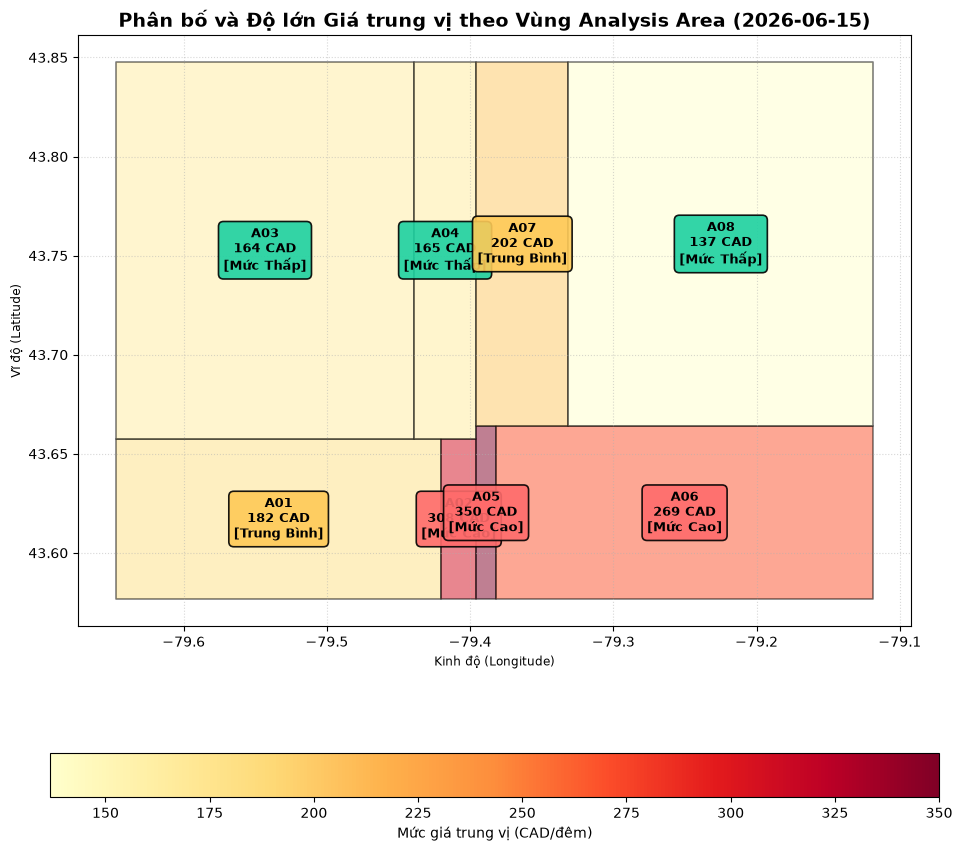

In [13]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

# 1. Khai báo 8 vùng chữ nhật (A01 - A08)
areas_data = [
    {"area": "A01", "lon_min": -79.647273, "lat_min": 43.57647011, "lon_max": -79.42006839, "lat_max": 43.6576896},
    {"area": "A02", "lon_min": -79.42006839, "lat_min": 43.57647011, "lon_max": -79.3957271, "lat_max": 43.6576896},
    {"area": "A03", "lon_min": -79.647273, "lat_min": 43.6576896, "lon_max": -79.439125, "lat_max": 43.84774},
    {"area": "A04", "lon_min": -79.439125, "lat_min": 43.6576896, "lon_max": -79.3957271, "lat_max": 43.84774},
    {"area": "A05", "lon_min": -79.3957271, "lat_min": 43.57647011, "lon_max": -79.38195595, "lat_max": 43.66403359},
    {"area": "A06", "lon_min": -79.38195595, "lat_min": 43.57647011, "lon_max": -79.11849, "lat_max": 43.66403359},
    {"area": "A07", "lon_min": -79.3957271, "lat_min": 43.66403359, "lon_max": -79.33134033, "lat_max": 43.84774},
    {"area": "A08", "lon_min": -79.33134033, "lat_min": 43.66403359, "lon_max": -79.11849, "lat_max": 43.84774},
]

boxes = [{"analysis_area": item["area"], "geometry": box(item["lon_min"], item["lat_min"], item["lon_max"], item["lat_max"])} for item in areas_data]
gdf_areas = gpd.GeoDataFrame(boxes, crs="EPSG:4326")

# 2. Đọc listings và tính Median Price mốc cuối

final_snapshot = "2026-06-15"

df_final = df_listings[(df_listings['snapshot_date'] == final_snapshot) & (df_listings['price'].notna())]
area_stats = df_final.groupby('analysis_area')['price'].median().reset_index()
area_stats.rename(columns={'price': 'median_price'}, inplace=True)

gdf_merged = gdf_areas.merge(area_stats, on='analysis_area', how='left')

# 3. Tính các ngưỡng phân loại độ lớn (Mức Thấp < 33%, Trung Bình 33-66%, Cao > 66%)
q33 = gdf_merged['median_price'].quantile(0.33)
q66 = gdf_merged['median_price'].quantile(0.66)

def classify_magnitude(price):
    if pd.isna(price):
        return "N/A", "lightgray"
    if price >= q66:
        return "Mức Cao", "#ff6b6b"      # Màu đỏ nhạt
    elif price >= q33:
        return "Trung Bình", "#feca57"    # Màu vàng cam nhạt
    else:
        return "Mức Thấp", "#1dd1a1"     # Màu xanh lá nhạt

# 4. Vẽ bản đồ
fig, ax = plt.subplots(figsize=(13, 9))

gdf_merged.plot(
    column='median_price',
    cmap='YlOrRd',
    alpha=0.5,
    edgecolor='black',
    linewidth=1.2,
    ax=ax,
    legend=True,
    legend_kwds={'label': 'Mức giá trung vị (CAD/đêm)', 'orientation': 'horizontal', 'shrink': 0.7}
)

# 5. Ghi chú Tên vùng + Giá trung vị + Phân loại độ lớn
for _, row in gdf_merged.iterrows():
    centroid = row.geometry.centroid
    area_code = row['analysis_area']
    price = row['median_price']
    
    tier_label, box_color = classify_magnitude(price)
    
    if pd.notna(price):
        label_text = f"{area_code}\n{price:,.0f} CAD\n[{tier_label}]"
    else:
        label_text = f"{area_code}\nN/A"
    
    ax.annotate(
        text=label_text,
        xy=(centroid.x, centroid.y),
        ha='center',
        va='center',
        fontsize=9,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.4', fc=box_color, ec='black', lw=1.2, alpha=0.9)
    )

ax.set_title(f"Phân bố và Độ lớn Giá trung vị theo Vùng Analysis Area ({final_snapshot})", fontsize=14, fontweight='bold')
ax.set_xlabel("Kinh độ (Longitude)")
ax.set_ylabel("Vĩ độ (Latitude)")
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

## 2.3 Median price theo loại phòng

In [14]:
last_snap_df.groupby('room_type')['price'].median()

room_type
Entire home/apt    251.06
Private room        89.01
Name: price, dtype: float64

# 3. Tỉ lệ entire home

## 3.1 Theo snapshot_date

In [15]:
room_type_df = df_listings[df_listings['room_type'].notna() & (df_listings['room_type'] != '')].copy()
room_type_df['is_entire_home'] = (room_type_df['room_type'] == 'Entire home/apt').astype(int)

In [16]:
room_type_theo_snapshot = room_type_df.groupby('snapshot_date').agg(
        entire_home_count=('is_entire_home', 'sum'),
        valid_room_type_total=('is_entire_home', 'count'),
        entire_home_share=('is_entire_home', 'mean')  # mean của mảng 0/1 = sum / count
    ).reset_index()


In [17]:
room_type_theo_snapshot


,snapshot_date,entire_home_count,valid_room_type_total,entire_home_share
0,2025-09-11,875,1000,0.875
1,2025-12-12,875,1000,0.875
2,2026-03-19,875,1000,0.875
3,2026-06-15,875,1000,0.875


In [18]:
room_type_theo_khuvuc = room_type_df.groupby('analysis_area').agg(
        entire_home_count=('is_entire_home', 'sum'),
        valid_room_type_total=('is_entire_home', 'count'),
        entire_home_share=('is_entire_home', 'mean')  # mean của mảng 0/1 = sum / count
    ).reset_index()


In [19]:
room_type_theo_khuvuc

,analysis_area,entire_home_count,valid_room_type_total,entire_home_share
0,A01,440,520,0.846154
1,A02,488,520,0.938462
2,A03,380,504,0.753968
3,A04,404,484,0.834711
4,A05,468,480,0.975000
5,A06,456,484,0.942149
6,A07,480,520,0.923077
7,A08,384,488,0.786885


# 4. Tỉ lệ multihost

In [20]:
# -------------------------------------------------------------------
def calc_kpi4_multi_host(df_listings):
    # Lọc dòng có host_id hợp lệ
    valid = df_listings[df_listings['host_id'].notna() & (df_listings['host_id'] != '')].copy()
    
    # Đếm số listing của từng host trong mỗi snapshot
    host_counts = valid.groupby(['snapshot_date', 'host_id'])['listing_id'].transform('count')
    valid['is_multi_host'] = host_counts > 1
    
    # Tỷ lệ = số listing thuộc host đa chỗ ở / tổng số listing có host hợp lệ
    kpi4 = valid.groupby('snapshot_date')['is_multi_host'].mean().reset_index(name='multi_listing_host_share')
    return kpi4

In [21]:
calc_kpi4_multi_host(df_listings)

,snapshot_date,multi_listing_host_share
0,2025-09-11,0.117
1,2025-12-12,0.117
2,2026-03-19,0.107
3,2026-06-15,0.116


In [22]:
"""TV3 — Nguyễn Quốc Hiếu: Phân tích không gian & Trực quan hóa thị trường Airbnb Toronto."""
from pathlib import Path
import matplotlib.pyplot as plt
import geopandas as gpd
import pandas as pd
from shapely.geometry import box
from statistics import median

OWNER = 'TV3 — Nguyễn Quốc Hiếu'
READY = True

# Tọa độ 8 vùng chữ nhật trong workbook của Toronto
TORONTO_AREAS = [
    {"area": "A01", "lon_min": -79.647273, "lat_min": 43.57647011, "lon_max": -79.42006839, "lat_max": 43.6576896},
    {"area": "A02", "lon_min": -79.42006839, "lat_min": 43.57647011, "lon_max": -79.3957271, "lat_max": 43.6576896},
    {"area": "A03", "lon_min": -79.647273, "lat_min": 43.6576896, "lon_max": -79.439125, "lat_max": 43.84774},
    {"area": "A04", "lon_min": -79.439125, "lat_min": 43.6576896, "lon_max": -79.3957271, "lat_max": 43.84774},
    {"area": "A05", "lon_min": -79.3957271, "lat_min": 43.57647011, "lon_max": -79.38195595, "lat_max": 43.66403359},
    {"area": "A06", "lon_min": -79.38195595, "lat_min": 43.57647011, "lon_max": -79.11849, "lat_max": 43.66403359},
    {"area": "A07", "lon_min": -79.3957271, "lat_min": 43.66403359, "lon_max": -79.33134033, "lat_max": 43.84774},
    {"area": "A08", "lon_min": -79.33134033, "lat_min": 43.66403359, "lon_max": -79.11849, "lat_max": 43.84774},
]

def _classify_tier(price, q33, q66):
    if price is None:
        return "N/A", "#e0e0e0"
    if price >= q66:
        return "Cao", "#ff7675"
    elif price >= q33:
        return "TB", "#ffeaa7"
    else:
        return "Thấp", "#55efc4"

def render(tables, figures, cfg):
    """Vẽ toàn bộ hình phân tích không gian và lưu vào thư mục figures."""
    figures = Path(figures)
    figures.mkdir(parents=True, exist_ok=True)
    saved_paths = []

    final_snapshot = cfg['snapshots'][-1]
    currency = cfg.get('currency', 'CAD')
    listings = tables.get('listings', [])

    # =========================================================================
    # HÌNH 1: Bản đồ 8 vùng Analysis Area kèm Tên + Giá trung vị + Độ lớn
    # =========================================================================
    prices_by_area = {}
    for r in listings:
        if r['snapshot_date'] == final_snapshot and r.get('analysis_area') and r.get('price') is not None:
            prices_by_area.setdefault(r['analysis_area'], []).append(r['price'])

    area_medians = {area: median(plist) for area, plist in prices_by_area.items() if plist}
    all_prices = sorted(area_medians.values()) if area_medians else []
    q33 = all_prices[len(all_prices) // 3] if all_prices else 0
    q66 = all_prices[(2 * len(all_prices)) // 3] if all_prices else 0

    boxes = []
    for item in TORONTO_AREAS:
        area_code = item["area"]
        geom = box(item["lon_min"], item["lat_min"], item["lon_max"], item["lat_max"])
        med_p = area_medians.get(area_code)
        tier, color = _classify_tier(med_p, q33, q66)
        boxes.append({
            "analysis_area": area_code,
            "median_price": med_p,
            "tier": tier,
            "color": color,
            "geometry": geom
        })
    gdf_areas = gpd.GeoDataFrame(boxes, crs="EPSG:4326")

    fig1, ax1 = plt.subplots(figsize=(11, 8))
    gdf_areas.plot(
        column="median_price",
        cmap="YlOrRd",
        alpha=0.45,
        edgecolor="black",
        linewidth=1.2,
        ax=ax1,
        legend=True,
        legend_kwds={'label': f"Giá trung vị ({currency}/đêm)", 'orientation': "horizontal", 'pad': 0.03}
    )

    # Chồng các điểm listing thực tế
    valid_points = [r for r in listings if r['snapshot_date'] == final_snapshot and r.get('latitude') is not None]
    if valid_points:
        ax1.scatter(
            [p['longitude'] for p in valid_points],
            [p['latitude'] for p in valid_points],
            c='navy', s=8, alpha=0.5, label=f'Listings (n={len(valid_points)})'
        )

    for _, row in gdf_areas.iterrows():
        c = row.geometry.centroid
        area_code = row["analysis_area"]
        med_p = row["median_price"]
        tier = row["tier"]
        lbl = f"{area_code}\n{med_p:,.0f} {currency}\n[{tier}]" if med_p is not None else f"{area_code}\nN/A"
        ax1.annotate(
            lbl, xy=(c.x, c.y), ha="center", va="center", fontsize=8.5, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.3", fc=row["color"], ec="black", lw=1.1, alpha=0.9)
        )

    ax1.set_title(f"Phân bố Không gian & Giá Trung vị 8 vùng Analysis Area ({final_snapshot})", fontsize=12, fontweight='bold')
    ax1.set_xlabel("Kinh độ")
    ax1.set_ylabel("Vĩ độ")
    ax1.legend(loc='upper right')
    plt.grid(True, linestyle=":", alpha=0.5)

    path1 = figures / "fig_tv3_analysis_area_price_map.png"
    plt.savefig(path1, dpi=300, bbox_inches='tight')
    plt.close(fig1)
    saved_paths.append(path1)

    # =========================================================================
    # HÌNH 2: Bản đồ Choropleth Ranh giới Hành chính (GeoJSON)
    # =========================================================================
    root_path = figures.parent.parent
    geojson_path = root_path / cfg['paths']['raw'] / final_snapshot / "neighbourhoods.geojson"
    if geojson_path.exists():
        gdf_hoods = gpd.read_file(geojson_path)
        prices_by_hood = {}
        for r in listings:
            if r['snapshot_date'] == final_snapshot and r.get('neighbourhood_cleansed') and r.get('price') is not None:
                prices_by_hood.setdefault(r['neighbourhood_cleansed'], []).append(r['price'])

        df_stats = pd.DataFrame([
            {'neighbourhood_cleansed': hood, 'median_price': median(plist)}
            for hood, plist in prices_by_hood.items()
        ])

        gdf_merged = gdf_hoods.merge(df_stats, left_on='neighbourhood', right_on='neighbourhood_cleansed', how='left')

        fig2, ax2 = plt.subplots(figsize=(12, 8))
        gdf_merged.plot(
            column='median_price', cmap='YlOrRd', linewidth=0.5, ax=ax2, edgecolor='0.3',
            legend=True, legend_kwds={'label': f"Giá trung vị ({currency}/đêm)", 'orientation': "horizontal", 'pad': 0.02},
            missing_kwds={'color': '#e0e0e0', 'label': 'Khuyết mẫu'}
        )
        ax2.set_title(f"Bản đồ Choropleth Giá Trung vị theo Ranh giới Hành chính ({final_snapshot})", fontsize=12, fontweight='bold')
        ax2.set_axis_off()

        path2 = figures / "fig_tv3_neighbourhood_choropleth.png"
        plt.savefig(path2, dpi=300, bbox_inches='tight')
        plt.close(fig2)
        saved_paths.append(path2)

    # =========================================================================
    # HÌNH 3: Biểu đồ Cấu trúc Nguồn cung & Host Chuyên nghiệp theo Vùng
    # =========================================================================
    market_kpi = tables.get('market_kpi', [])
    final_kpis = [r for r in market_kpi if r['snapshot_date'] == final_snapshot]

    if final_kpis:
        df_kpi = pd.DataFrame(final_kpis).sort_values('analysis_area')
        fig3, ax3 = plt.subplots(figsize=(10, 5))
        
        x = range(len(df_kpi))
        width = 0.35
        
        entire_shares = [r.get('entire_home_share', 0) * 100 if r.get('entire_home_share') else 0 for r in final_kpis]
        host_shares = [r.get('multi_listing_host_share', 0) * 100 if r.get('multi_listing_host_share') else 0 for r in final_kpis]
        
        ax3.bar([i - width/2 for i in x], entire_shares, width, label='Tỷ lệ Entire Home (%)', color='#0984e3')
        ax3.bar([i + width/2 for i in x], host_shares, width, label='Tỷ lệ Host đa chỗ ở (%)', color='#e17055')
        
        ax3.set_xticks(list(x))
        ax3.set_xticklabels(df_kpi['analysis_area'])
        ax3.set_ylabel("Tỷ lệ (%)")
        ax3.set_title(f"So sánh Cấu trúc Phòng & Host theo Vùng Analysis Area ({final_snapshot})", fontsize=12, fontweight='bold')
        ax3.legend()
        plt.grid(axis='y', linestyle=":", alpha=0.6)

        path3 = figures / "fig_tv3_spatial_structure.png"
        plt.savefig(path3, dpi=300, bbox_inches='tight')
        plt.close(fig3)
        saved_paths.append(path3)

    return saved_paths

In [23]:
# Cell 1: Import thư viện Plotly và chuẩn bị dữ liệu
import json
from pathlib import Path
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

FINAL_SNAPSHOT = '2026-06-15'
CURRENCY = 'CAD'

# 1. Đọc dữ liệu listings
df_listings = pd.read_csv('../data/processed/real/listings.csv')
df_final = df_listings[df_listings['snapshot_date'] == FINAL_SNAPSHOT].copy()

# 2. Đọc file GeoJSON ranh giới khu vực hành chính Toronto
geojson_path = Path(f'../data/raw/{FINAL_SNAPSHOT}/neighbourhoods.geojson')
with open(geojson_path, 'r', encoding='utf-8') as f:
    toronto_geojson = json.load(f)

print(f"Đã nạp {len(df_final)} listing mốc cuối ({FINAL_SNAPSHOT})")

Đã nạp 1000 listing mốc cuối (2026-06-15)


In [24]:
areas_data = [
    {"area": "A01", "lon_min": -79.647273, "lat_min": 43.57647011, "lon_max": -79.42006839, "lat_max": 43.6576896},
    {"area": "A02", "lon_min": -79.42006839, "lat_min": 43.57647011, "lon_max": -79.3957271, "lat_max": 43.6576896},
    {"area": "A03", "lon_min": -79.647273, "lat_min": 43.6576896, "lon_max": -79.439125, "lat_max": 43.84774},
    {"area": "A04", "lon_min": -79.439125, "lat_min": 43.6576896, "lon_max": -79.3957271, "lat_max": 43.84774},
    {"area": "A05", "lon_min": -79.3957271, "lat_min": 43.57647011, "lon_max": -79.38195595, "lat_max": 43.66403359},
    {"area": "A06", "lon_min": -79.38195595, "lat_min": 43.57647011, "lon_max": -79.11849, "lat_max": 43.66403359},
    {"area": "A07", "lon_min": -79.3957271, "lat_min": 43.66403359, "lon_max": -79.33134033, "lat_max": 43.84774},
    {"area": "A08", "lon_min": -79.33134033, "lat_min": 43.66403359, "lon_max": -79.11849, "lat_max": 43.84774},
]

boxes = [
    {"analysis_area": item["area"], "geometry": box(item["lon_min"], item["lat_min"], item["lon_max"], item["lat_max"])}
    for item in areas_data
]
gdf_areas = gpd.GeoDataFrame(boxes, crs="EPSG:4326")

In [25]:
# Cell 4: Tính toán các KPI cốt lõi ở mốc cuối theo 8 vùng Analysis Area
df_final = df_listings[df_listings['snapshot_date'] == FINAL_SNAPSHOT].copy()

# 1. Supply & Median Price
price_stats = df_final.groupby('analysis_area').agg(
    supply=('listing_id', 'count'),
    median_price=('price', 'median'),
    price_n=('price', 'count')
).reset_index()

# 2. Entire Home Share (Mẫu số = các dòng có room_type hợp lệ)
valid_room = df_final[df_final['room_type'].notna() & (df_final['room_type'] != '')]
room_stats = valid_room.groupby('analysis_area').apply(
    lambda g: (g['room_type'] == 'Entire home/apt').mean(),
    include_groups=False
).reset_index(name='entire_home_share')

# 3. Multi-listing Host Share (Host có > 1 listing trong mốc)
valid_host = df_final[df_final['host_id'].notna() & (df_final['host_id'] != '')].copy()
host_counts = valid_host.groupby('host_id')['listing_id'].transform('count')
valid_host['is_multi_host'] = host_counts > 1
host_stats = valid_host.groupby('analysis_area')['is_multi_host'].mean().reset_index(name='multi_listing_host_share')

# Gom hợp thành 1 bảng tổng hợp KPI
df_kpi_summary = price_stats.merge(room_stats, on='analysis_area', how='left')
df_kpi_summary = df_kpi_summary.merge(host_stats, on='analysis_area', how='left')

df_kpi_summary

,analysis_area,supply,median_price,price_n,entire_home_share,multi_listing_host_share
0,A01,130,181.655,128,0.846154,0.138462
1,A02,130,308.120,127,0.938462,0.061538
2,A03,126,164.170,125,0.753968,0.039683
3,A04,121,165.190,120,0.834711,0.148760
4,A05,120,350.000,115,0.975000,0.208333
5,A06,121,269.000,117,0.942149,0.082645
6,A07,130,202.450,129,0.923077,0.138462
7,A08,122,136.710,119,0.786885,0.114754


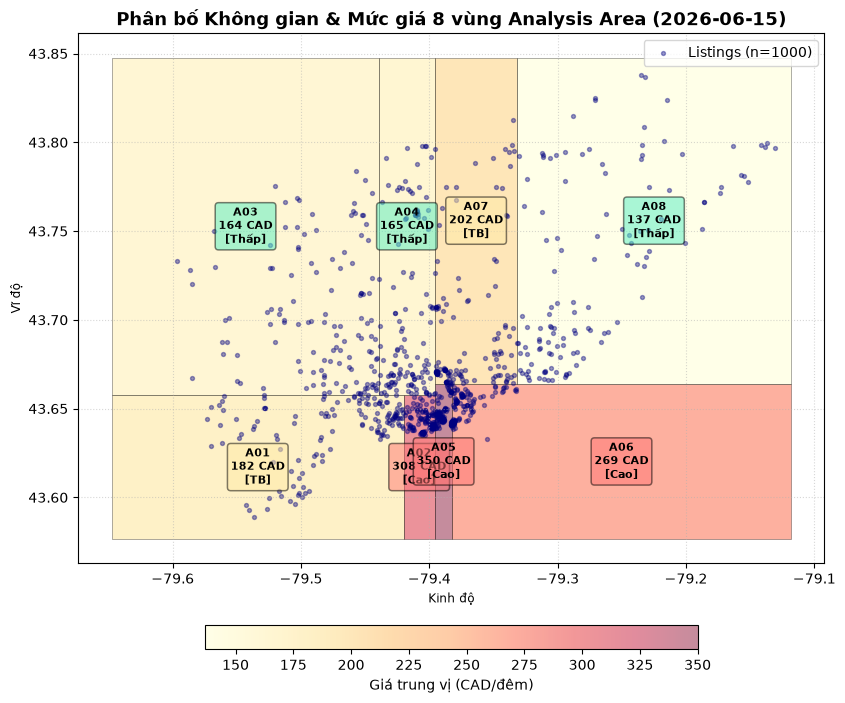

In [59]:
# Cell 5: Bản đồ 1 - Phân bố 8 vùng A01-A08 kèm Nhãn Giá & Phân loại Độ lớn (Cao/TB/Thấp)
from matplotlib import cm
from matplotlib.colors import Normalize
gdf_map1 = gdf_areas.merge(df_kpi_summary, on='analysis_area', how='left')

# Phân vị 33% và 66% để xếp cấp độ
q33 = gdf_map1['median_price'].quantile(0.33)
q66 = gdf_map1['median_price'].quantile(0.66)

vmin, vmax = gdf_map1['median_price'].min(), gdf_map1['median_price'].max()

def get_tier(p):
    if pd.isna(p): return "N/A", "#e0e0e0"
    if p >= q66: return "Cao", "#ff7675"
    elif p >= q33: return "TB", "#ffeaa7"
    else: return "Thấp", "#55efc4"

fig, ax = plt.subplots(figsize=(12, 8))

# Vẽ 8 khung vùng
gdf_map1.plot(
    column='median_price', cmap='YlOrRd', alpha=0.45,
    edgecolor='black', linewidth=0.5, ax=ax, legend=False,
)

sm = cm.ScalarMappable(norm=Normalize(vmin=vmin, vmax=vmax), cmap='YlOrRd')
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', pad=0.10, fraction=0.04, shrink=0.8, alpha=0.45)
cbar.set_label(f'Giá trung vị ({CURRENCY}/đêm)')

# Chồng các điểm listing thực tế
valid_pts = df_final[df_final['latitude'].notna() & df_final['longitude'].notna()]
ax.scatter(valid_pts['longitude'], valid_pts['latitude'], c='navy', s=8, alpha=0.4, label=f'Listings (n={len(valid_pts)})')

# Thêm nhãn tên vùng, giá và độ lớn
for _, row in gdf_map1.iterrows():
    c = row.geometry.centroid
    area = row['analysis_area']
    p = row['median_price']
    tier, box_color = get_tier(p)
    
    lbl = f"{area}\n{p:,.0f} {CURRENCY}\n[{tier}]" if pd.notna(p) else f"{area}\nN/A"
    ax.annotate(lbl, xy=(c.x, c.y), ha='center', va='center', fontsize=8, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', fc=box_color, ec='black', lw=1.1, alpha=0.5))

ax.set_title(f"Phân bố Không gian & Mức giá 8 vùng Analysis Area ({FINAL_SNAPSHOT})", fontsize=13, fontweight='bold')
ax.set_xlabel("Kinh độ")
ax.set_ylabel("Vĩ độ")
ax.legend(loc='upper right')

plt.grid(True, linestyle=":", alpha=0.5)
plt.show()

In [54]:
# Cell 3: Bản đồ Choropleth Tương tác Tô màu Ranh giới Hành chính (GeoJSON) theo Giá trung vị
# Tính Giá trung vị & Số lượng nguồn cung theo khu vực hành chính
hood_stats = df_final[df_final['price'].notna()].groupby('neighbourhood_cleansed').agg(
    median_price=('price', 'median'),
    supply=('listing_id', 'count')
).reset_index()

fig_choropleth = px.choropleth_mapbox(
    hood_stats,
    geojson=toronto_geojson,
    locations='neighbourhood_cleansed',
    featureidkey="properties.neighbourhood",  # Ghép với thuộc tính 'neighbourhood' trong GeoJSON
    color='median_price',
    color_continuous_scale="YlOrRd",
    range_color=(hood_stats['median_price'].min(), hood_stats['median_price'].quantile(0.95)),
    mapbox_style="open-street-map",
    zoom=9.8,
    center={"lat": 43.70, "lon": -79.38},
    opacity=0.7,
    labels={'median_price': f'Giá trung vị ({CURRENCY})', 'supply': 'Số listing', 'neighbourhood_cleansed': 'Khu vực'},
    hover_data={'neighbourhood_cleansed': True, 'median_price': ':$,.0f', 'supply': True},
    title=f"<b>Bản đồ Choropleth Tương tác: Giá Trung vị theo Khu vực Hành chính ({FINAL_SNAPSHOT})</b>"
)

fig_choropleth.update_layout(margin={"r":0,"t":40,"l":0,"b":0}, height=600)



/tmp/ipykernel_207857/730566270.py:8: DeprecationWarning: *choropleth_mapbox* is deprecated! Use *choropleth_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/
  fig_choropleth = px.choropleth_mapbox(


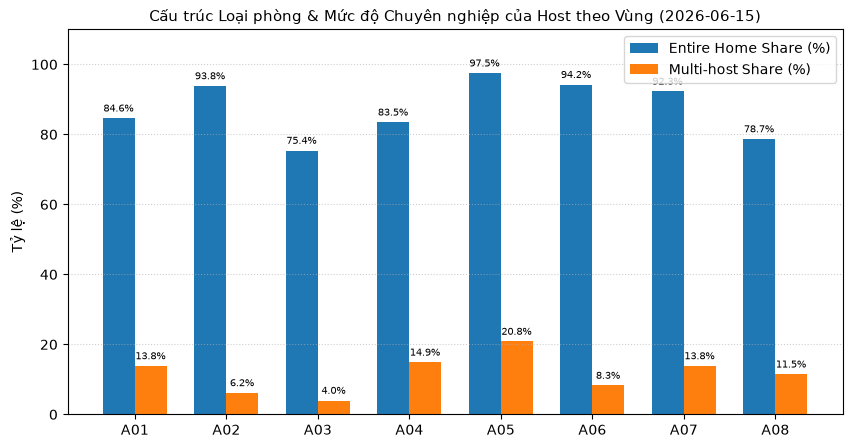

In [ ]:
# Cell 7: Biểu đồ cột - So sánh Entire Home Share và Multi-listing Host Share giữa 8 vùng

fig, ax = plt.subplots(figsize=(10, 5))

df_kpi_sorted = df_kpi_summary.sort_values("analysis_area")
x = range(len(df_kpi_sorted))
width = 0.35

ax.bar(
    [i - width / 2 for i in x],
    df_kpi_sorted["entire_home_share"] * 100,
    width,
    label="Entire Home Share (%)",
)
ax.bar(
    [i + width / 2 for i in x],
    df_kpi_sorted["multi_listing_host_share"] * 100,
    width,
    label="Multi-host Share (%)",
)

# THÊM DÒNG NÀY: Tự động hiển thị số liệu chính xác trên đầu các cột
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=7.5)

ax.set_xticks(list(x))
ax.set_xticklabels(df_kpi_sorted["analysis_area"])
ax.set_ylabel("Tỷ lệ (%)")
ax.set_title(
    f"Cấu trúc Loại phòng & Mức độ Chuyên nghiệp của Host theo Vùng ({FINAL_SNAPSHOT})",
    fontsize=11,
)

# Mở rộng giới hạn trục Y một chút để số liệu ở cột cao nhất không bị che bởi khung
ax.set_ylim(0, 110)

ax.legend()
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.show()